# 06 - Zero-forcing equalisation and max-log soft demapping
**Objective.** Undo the fading with a ZF equaliser and turn the equalised symbols into **bit LLRs** that carry the *reliability* of each bit to the Viterbi decoder.

## Zero forcing
$y=hx+n \;\Rightarrow\; \hat x=y/h = x + n/h$. The channel is removed completely, but the noise is scaled: its variance becomes $N_0/|h|^2$.
* **Deep fades** ($|h|\to0$) blow the noise up. Numerically we floor $|h|\ge\varepsilon=10^{-3}$ (keeping the phase) so no division overflows.
* **Limitations:** noise enhancement (for Rayleigh, $E[1/|h|^2]=\infty$); with one antenna ZF is plain channel inversion and is not MMSE-optimal at low SNR; it needs perfect CSI.

## Max-log LLR
$$\text{LLR}_k=\ln\frac{P(b_k=0|\hat x)}{P(b_k=1|\hat x)}\approx\frac{\min_{s:b_k=1}|\hat x-s|^2-\min_{s:b_k=0}|\hat x-s|^2}{N_{0,\text{eff}}},\qquad N_{0,\text{eff}}=\frac{N_0}{|h|^2}.$$
Positive $\Rightarrow$ bit 0. Dividing by $N_{0,\text{eff}}$ is what makes a bit received in a deep fade have an LLR near 0 ("don't trust me"), which is exactly what lets the Viterbi decoder ride through faded blocks.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # project root = import root
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
print("project root:", ROOT)

project root: /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1


In [2]:
from task1_conventional import channel as ch
from task1_conventional.equalizer import zf_equalize
from task1_conventional.demapper import llr_maxlog
from task1_conventional.modulation import Modem
rng = np.random.default_rng(3)

## 1. ZF on a faded constellation

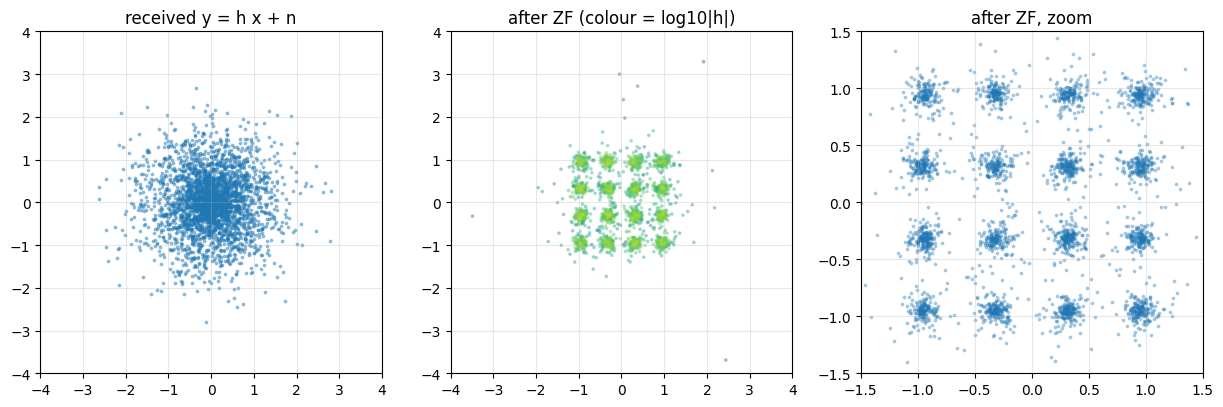

ZF restores the grid for strong |h| but smears points from deep fades far away (noise enhancement).


In [3]:
m = Modem("16QAM"); tx = rng.integers(0, 2, 4 * 3000); x = m.modulate(tx); snr = 22.0
ids = np.arange(len(x)) // 1; y, h, n0 = ch.rayleigh_block_fading(x, snr, ids, len(x), rng); xh, gain = zf_equalize(y, h)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].scatter(y.real, y.imag, s=3, alpha=0.4); ax[0].set_title("received y = h x + n"); lim = 4
ax[1].scatter(xh.real, xh.imag, s=3, alpha=0.3, c=np.log10(abs(h)), cmap="viridis"); ax[1].set_title("after ZF (colour = log10|h|)")
ax[2].scatter(xh.real, xh.imag, s=3, alpha=0.3); ax[2].set_title("after ZF, zoom"); ax[2].set_xlim(-1.5, 1.5); ax[2].set_ylim(-1.5, 1.5)
for a in ax[:2]: a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
for a in ax: a.set_aspect("equal")
plt.show()
print("ZF restores the grid for strong |h| but smears points from deep fades far away (noise enhancement).")

## 2. Noise enhancement and the deep-fade guard

In [4]:
err = abs(xh - x) ** 2
bins = [0, 0.05, 0.1, 0.2, 0.5, 1, 2, 10]; cat = pd.cut(abs(h) ** 2, bins)
tab = pd.DataFrame({"|h|^2 bin": cat, "mean |xhat - x|^2": err, "theory N0/|h|^2 (mean)": n0 / abs(h) ** 2}).groupby("|h|^2 bin", observed=True).mean()
display(tab)
h0 = np.array([0j, 1e-12 + 0j, 1e-4 + 0j, 1.0 + 0j]); xz, gz = zf_equalize(np.ones(4, complex), h0)
print("guarded division with h =", h0, "\n  x_hat =", xz, "\n  finite:", np.all(np.isfinite(xz)))

,mean |xhat - x|^2,theory N0/|h|^2 (mean)
|h|^2 bin,,
"(0.0, 0.05]",1.675096,2.472398
"(0.05, 0.1]",0.083381,0.086760
"(0.1, 0.2]",0.040268,0.043646
"(0.2, 0.5]",0.018976,0.019456
"(0.5, 1.0]",0.008677,0.009018
"(1.0, 2.0]",0.004405,0.004615
"(2.0, 10.0]",0.002264,0.002300


guarded division with h = [0.e+00+0.j 1.e-12+0.j 1.e-04+0.j 1.e+00+0.j] 
  x_hat = [1000.+0.j 1000.+0.j 1000.+0.j    1.+0.j] 
  finite: True


## 3. LLR sign convention (known bits, noiseless and noisy)

In [5]:
rows = []
for n in ["BPSK", "QPSK", "16QAM", "64QAM"]:
    mo = Modem(n); b = rng.integers(0, 2, mo.bps * 2000); s = mo.modulate(b)
    l_clean = llr_maxlog(s, 0.01, mo); y_, n0_ = ch.awgn(s, 12.0, rng); l_noisy = llr_maxlog(y_, n0_, mo)
    rows.append(dict(modulation=n, noiseless_sign_correct=bool(np.all((l_clean < 0) == (b == 1))),
                     frac_sign_errors_12dB=float(np.mean((l_noisy < 0) != (b == 1))),
                     mean_LLR_given_bit0=float(l_noisy[b == 0].mean()), mean_LLR_given_bit1=float(l_noisy[b == 1].mean())))
display(pd.DataFrame(rows))

,modulation,noiseless_sign_correct,frac_sign_errors_12dB,mean_LLR_given_bit0,mean_LLR_given_bit1
0,BPSK,True,0.000000,63.111226,-63.059109
1,QPSK,True,0.000250,31.809097,-31.909873
2,16QAM,True,0.031000,11.244189,-10.952625
3,64QAM,True,0.115667,5.492641,-5.490891


## 4. Reliability differs per bit position (16-QAM, Gray)

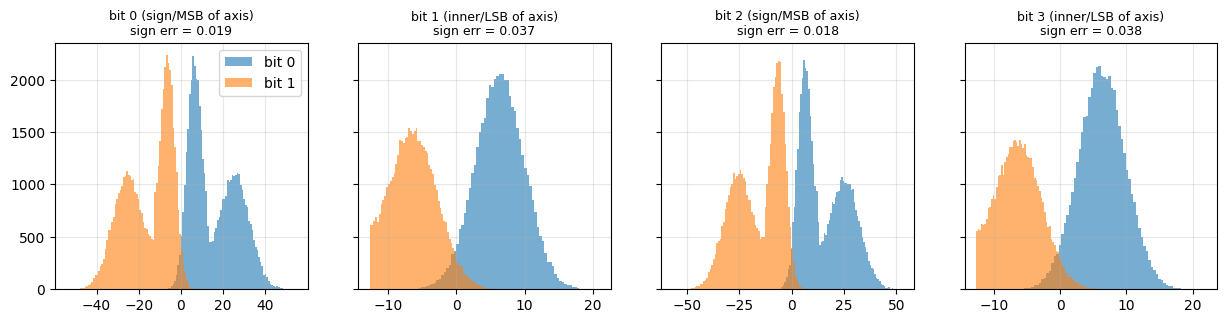

The 2nd bit of every axis (inner bit) is less reliable: its two decision regions are closer together.


In [6]:
mo = Modem("16QAM"); b = rng.integers(0, 2, 4 * 100000); y_, n0_ = ch.awgn(mo.modulate(b), 12.0, rng)
L = llr_maxlog(y_, n0_, mo).reshape(-1, 4); B = b.reshape(-1, 4)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for k in range(4):
    ax[k].hist(L[B[:, k] == 0, k], bins=80, alpha=0.6, label="bit 0"); ax[k].hist(L[B[:, k] == 1, k], bins=80, alpha=0.6, label="bit 1")
    ax[k].set_title(f"bit {k} ({'sign/MSB' if k % 2 == 0 else 'inner/LSB'} of axis)\nsign err = {np.mean((L[:, k] < 0) != (B[:, k] == 1)):.3f}", fontsize=9)
ax[0].legend(); plt.show()
print("The 2nd bit of every axis (inner bit) is less reliable: its two decision regions are closer together.")

## 5. LLR magnitude follows the channel quality

In [7]:
mo = Modem("QPSK"); b = rng.integers(0, 2, 2 * 50000); x = mo.modulate(b); ids = np.arange(len(x))
y, h, n0 = ch.rayleigh_block_fading(x, 10.0, ids, len(x), rng); xh, gain = zf_equalize(y, h)
L_zf = llr_maxlog(xh, n0 / gain, mo).reshape(-1, 2); L_naive = llr_maxlog(xh, n0, mo).reshape(-1, 2)   # naive: ignores |h|
B = b.reshape(-1, 2); bins = pd.cut(abs(h) ** 2, [0, 0.05, 0.2, 0.5, 1, 2, 10])
out = pd.DataFrame({"|h|^2": bins, "mean |LLR| (with CSI)": abs(L_zf[:, 0]), "bit err": (L_zf[:, 0] < 0) != (B[:, 0] == 1)}).groupby("|h|^2", observed=True).mean()
display(out)
print("With CSI the weak-channel bits get small |LLR| although their hard-decision error rate is high; ignoring CSI (N0 instead of N0/|h|^2)\nwould give them large, *wrong-confidence* LLRs and degrade the Viterbi decoder - this is why the demapper receives the equaliser gain.")

,mean |LLR| (with CSI),bit err
|h|^2,,
"(0.0, 0.05]",0.871410,0.299325
"(0.05, 0.2]",2.808118,0.132595
"(0.2, 0.5]",7.047611,0.035871
"(0.5, 1.0]",14.681562,0.004518
"(1.0, 2.0]",28.375062,0.000168
"(2.0, 10.0]",59.774787,0.000000


With CSI the weak-channel bits get small |LLR| although their hard-decision error rate is high; ignoring CSI (N0 instead of N0/|h|^2)
would give them large, *wrong-confidence* LLRs and degrade the Viterbi decoder - this is why the demapper receives the equaliser gain.
